# 11 — Attention from scratch: forward, backward, multi-head, and a transformer forecaster

**Goal:** the P2 exit check of your roadmap, done in code. Derive and implement scaled dot-product attention in NumPy
(forward **and** backward), prove the role of `√d_k` by experiment, build multi-head attention that matches
`nn.MultiheadAttention` to 1e-6, then a small causal transformer that forecasts a time series and beats the naive
baselines from Tomin's forecasting book. Along the way: why the causal mask is a **leakage** control.
**Time:** ~5 h (two sessions: Parts 1–3, then 4–6). **Level:** 4 / 5.
**Interview relevance:** "implement single- and multi-head attention, then add a causal mask" is a real ML intern
interview question. After this notebook, do it again in a blank file in under 25 minutes.

Shapes notation: `B` batch, `T` sequence length, `C` model width, `h` heads, `d = C / h` head size.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

rng = np.random.default_rng(0)
torch.manual_seed(0)

def check(cond, msg):
    assert cond, "❌ " + msg
    print("✅", msg)

## Part 1 — Scaled dot-product attention in NumPy

`Attention(Q, K, V) = softmax(QKᵀ / √d) V`, with `Q, K: (B, T, d)`, `V: (B, T, d_v)`.
With `causal=True`, position `t` may only attend to positions `≤ t`: set the masked scores to `−inf` before the
softmax.

**✍️ Predict before running.** Shape of `Q @ K.transpose(0, 2, 1)`? Which entries does the causal mask remove (above or below the diagonal)? What is row 0 of the attention matrix with a causal mask, whatever the input?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [2]:
def softmax(S, axis=-1):
    """Stable softmax; must handle rows containing -inf."""
    S = S - S.max(axis=axis, keepdims=True)
    E = np.exp(S)
    return E / E.sum(axis=axis, keepdims=True)

def attention(Q, K, V, causal=False):
    """Returns (out, P): out (B, T, d_v), attention weights P (B, T, T). Hint: np.triu(..., k=1) builds the mask."""
    d = Q.shape[-1]
    S = Q @ K.transpose(0, 2, 1) / np.sqrt(d)
    if causal:
        T = S.shape[-1]
        S = np.where(np.triu(np.ones((T, T), dtype=bool), k=1), -np.inf, S)
    P = softmax(S)
    return P @ V, P

In [3]:
B, T, d = 2, 6, 8
Q, K, V = (rng.normal(size=(B, T, d)) for _ in range(3))
to_t = lambda a: torch.tensor(a)
for causal in [False, True]:
    out, P = attention(Q, K, V, causal)
    ref = F.scaled_dot_product_attention(to_t(Q), to_t(K), to_t(V), is_causal=causal).numpy()
    check(np.allclose(out, ref), f"matches torch scaled_dot_product_attention (causal={causal})")
check(np.allclose(P.sum(-1), 1) and np.allclose(np.triu(P[0], 1), 0), "rows sum to 1, nothing above the diagonal")

✅ matches torch scaled_dot_product_attention (causal=False)
✅ matches torch scaled_dot_product_attention (causal=True)
✅ rows sum to 1, nothing above the diagonal


### Two properties worth knowing by heart (checked, not trusted)

1. **Causality:** with the mask, changing the input at position 4 must not change outputs at positions 0–3.
2. **Permutation equivariance:** without a mask and without positional information, attention does not know the order
   of tokens: permuting the input rows permutes the output rows the same way. That is *why* transformers need
   positional embeddings.

In [4]:
X = rng.normal(size=(1, T, d))
X2 = X.copy(); X2[0, 4] += 10
causality_ok = np.allclose(attention(X, X, X, True)[0][0, :4], attention(X2, X2, X2, True)[0][0, :4])
perm = rng.permutation(T)
equivariance_ok = np.allclose(attention(X[:, perm], X[:, perm], X[:, perm])[0], attention(X, X, X)[0][:, perm])
check(causality_ok, "causal attention: the future does not leak into the past")
check(equivariance_ok, "unmasked attention is permutation-equivariant (it has no notion of order)")

✅ causal attention: the future does not leak into the past
✅ unmasked attention is permutation-equivariant (it has no notion of order)


## Part 2 — Why divide by √d? An experiment

If the entries of `q` and `k` are independent with mean 0 and variance 1, then `q·k` has variance `d`. Large scores
saturate the softmax: it becomes nearly one-hot, and its gradient vanishes.

**✍️ Predict before running.** For d = 512 and T = 32 random tokens, what is the entropy of an attention row without scaling? With scaling? (Max entropy is log 32 ≈ 3.47.)

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [5]:
def row_entropy(P):
    """Mean entropy (natural log) of the rows of P, ignoring 0 * log 0."""
    return float(np.mean(-(P * np.log(np.where(P > 0, P, 1))).sum(-1)))

ds = [4, 16, 64, 256, 512]
variances, H_scaled, H_unscaled = [], [], []
for dd in ds:
    q, k = rng.normal(size=(20000, dd)), rng.normal(size=(20000, dd))
    variances.append(np.var((q * k).sum(1)))
    Qd, Kd = rng.normal(size=(200, 32, dd)), rng.normal(size=(200, 32, dd))
    S = Qd @ Kd.transpose(0, 2, 1)
    H_scaled.append(row_entropy(softmax(S / np.sqrt(dd)))); H_unscaled.append(row_entropy(softmax(S)))
for dd, v, hs, hu in zip(ds, variances, H_scaled, H_unscaled):
    print(f"d={dd:4d}  var(q·k)={v:7.1f}  entropy scaled={hs:.2f}  unscaled={hu:.2f}")
check(all(abs(v / dd - 1) < 0.1 for v, dd in zip(variances, ds)), "var(q·k) ≈ d")
check(H_unscaled[-1] < 0.5 and H_scaled[-1] > 0.8 * np.log(32), "without scaling the softmax collapses to one-hot as d grows")

d=   4  var(q·k)=    4.1  entropy scaled=3.03  unscaled=2.28
d=  16  var(q·k)=   16.1  entropy scaled=3.02  unscaled=1.12
d=  64  var(q·k)=   63.5  entropy scaled=3.01  unscaled=0.50
d= 256  var(q·k)=  253.7  entropy scaled=3.01  unscaled=0.24
d= 512  var(q·k)=  509.9  entropy scaled=3.01  unscaled=0.16
✅ var(q·k) ≈ d
✅ without scaling the softmax collapses to one-hot as d grows


## Part 3 — The backward pass of attention, by hand

Forward: `S = QKᵀ/√d` (masked), `P = softmax(S)`, `O = PV`. Given the upstream gradient `dO` (same shape as `O`),
derive on paper, then implement:
- `dV = Pᵀ dO`  ← check the shapes: `(B, T, T)ᵀ @ (B, T, d_v)`
- `dP = dO Vᵀ`
- softmax backward, row by row: `dS = P ⊙ (dP − Σⱼ dPⱼ Pⱼ)` ← **derive this one**: it is the "gradient of softmax"
  exit check of your roadmap
- `dQ = dS K / √d`, `dK = dSᵀ Q / √d`

Masked entries have `P = 0`, so they get `dS = 0` automatically.

In [6]:
def attention_backward(Q, K, V, dO, causal=False):
    """Returns dQ, dK, dV. Recompute P with attention() (that is what FlashAttention does too)."""
    _, P = attention(Q, K, V, causal)
    d = Q.shape[-1]
    dV = P.transpose(0, 2, 1) @ dO
    dP = dO @ V.transpose(0, 2, 1)
    dS = P * (dP - (dP * P).sum(-1, keepdims=True))
    dQ = dS @ K / np.sqrt(d)
    dK = dS.transpose(0, 2, 1) @ Q / np.sqrt(d)
    return dQ, dK, dV

In [7]:
dO = rng.normal(size=(B, T, d))
for causal in [False, True]:
    q, k, v = (torch.tensor(a, requires_grad=True) for a in (Q, K, V))
    (F.scaled_dot_product_attention(q, k, v, is_causal=causal) * torch.tensor(dO)).sum().backward()
    mine = attention_backward(Q, K, V, dO, causal)
    for name, g_mine, g_ref in zip("QKV", mine, (q.grad, k.grad, v.grad)):
        check(np.allclose(g_mine, g_ref.numpy()), f"d{name} matches autograd (causal={causal})")

✅ dQ matches autograd (causal=False)
✅ dK matches autograd (causal=False)
✅ dV matches autograd (causal=False)
✅ dQ matches autograd (causal=True)
✅ dK matches autograd (causal=True)
✅ dV matches autograd (causal=True)


## Part 4 — Multi-head self-attention in PyTorch

One `nn.Linear(C, 3C)` produces q, k, v for all heads at once. Split into `h` heads of size `d = C/h`:
`(B, T, C) → (B, T, h, d) → (B, h, T, d)`, attend per head (you may use your formula in torch, or
`F.scaled_dot_product_attention`), merge back to `(B, T, C)`, then an output projection `nn.Linear(C, C)`.

In [8]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, C, n_heads, causal=True):
        super().__init__()
        assert C % n_heads == 0
        self.h, self.causal = n_heads, causal
        self.qkv = nn.Linear(C, 3 * C)
        self.proj = nn.Linear(C, C)

    def forward(self, x):
        """x: (B, T, C) -> (B, T, C). Name the layers self.qkv and self.proj (the check copies their weights)."""
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v))   # (B, h, T, d)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=self.causal)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(y)

In [9]:
C, h, T = 32, 4, 10
mine = MultiHeadSelfAttention(C, h, causal=True).double()
ref = nn.MultiheadAttention(C, h, batch_first=True).double()
with torch.no_grad():
    ref.in_proj_weight.copy_(mine.qkv.weight); ref.in_proj_bias.copy_(mine.qkv.bias)
    ref.out_proj.weight.copy_(mine.proj.weight); ref.out_proj.bias.copy_(mine.proj.bias)
x = torch.randn(3, T, C, dtype=torch.float64)
mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
check(torch.allclose(mine(x), ref(x, x, x, attn_mask=mask, need_weights=False)[0]), "matches nn.MultiheadAttention with a causal mask")
n_params = sum(p.numel() for p in mine.parameters())
check(n_params == 4 * C * C + 4 * C, f"parameter count 4C² + 4C = {n_params} (does not depend on the number of heads)")

✅ matches nn.MultiheadAttention with a causal mask
✅ parameter count 4C² + 4C = 4224 (does not depend on the number of heads)


**✍️ Predict before running.** The parameter count does not depend on h. So what do several heads buy you compared with one head of size C? (Think: how many different attention patterns per layer.)

> Prediction:
>
> Confidence: [1] / [2] / [3]

## Part 5 — A transformer block and a causal forecaster

Pre-LayerNorm block (GPT-2 style):
```
x = x + MHSA(LN1(x))
x = x + MLP(LN2(x))          MLP: Linear(C, 4C) → GELU → Linear(4C, C)
```
The forecaster reads a window of `T` past values (one scalar per time step), embeds each with `nn.Linear(1, C)`, adds
a learned positional embedding `nn.Embedding(T, C)`, runs `n_layers` blocks, a final LayerNorm and `nn.Linear(C, 1)`.
Like GPT, it predicts **the next value at every position**: output `(B, T)` where output `t` estimates `y[t + 1]`.

In [10]:
class Block(nn.Module):
    def __init__(self, C, n_heads, causal=True):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(C), nn.LayerNorm(C)
        self.attn = MultiHeadSelfAttention(C, n_heads, causal)
        self.mlp = nn.Sequential(nn.Linear(C, 4 * C), nn.GELU(), nn.Linear(4 * C, C))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class Forecaster(nn.Module):
    def __init__(self, T, C=32, n_heads=4, n_layers=2, causal=True):
        super().__init__()
        self.inp = nn.Linear(1, C)
        self.pos = nn.Embedding(T, C)
        self.blocks = nn.Sequential(*[Block(C, n_heads, causal) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(C)
        self.head = nn.Linear(C, 1)

    def forward(self, x):
        """x: (B, T) float -> (B, T): prediction of the next value at every position."""
        T = x.shape[1]
        z = self.inp(x.unsqueeze(-1)) + self.pos(torch.arange(T, device=x.device))
        return self.head(self.ln(self.blocks(z))).squeeze(-1)

### Data: hourly signal with a daily and a weekly cycle

Think heart rate or activity from a wearable, simplified. **Split in time** (first 80 % train, last 20 % test): a random
split of overlapping windows would leak the test period into training.

In [11]:
n = 24 * 7 * 30                                  # 30 weeks, hourly
t = np.arange(n)
sigma = 0.3
y = np.sin(2 * np.pi * t / 24) + 0.5 * np.sin(2 * np.pi * t / 168) + sigma * rng.normal(size=n)
y = y.astype(np.float32)
split = int(0.8 * n)
T = 48

def make_windows(series, T):
    """All windows: X[i] = series[i : i+T], Y[i] = series[i+1 : i+T+1]. Returns two arrays of shape (N, T)."""
    N = len(series) - T
    idx = np.arange(T)[None, :] + np.arange(N)[:, None]
    return series[idx], series[idx + 1]

Xtr, Ytr = make_windows(y[:split], T)
Xte, Yte = make_windows(y[split:], T)
check(Xtr.shape == (split - T, T) and np.array_equal(Xtr[5, 1:], Ytr[5, :-1]), "windows and shifted targets")

✅ windows and shifted targets


### Baselines first (Hyndman's rule: never report a model without them)

Evaluate **one-step-ahead at the last position**: predict `Y[:, -1]` (the value right after the window) from `X`.
- naive: the last observed value
- seasonal naive: the value one day (24 h) before the target

**✍️ Predict before running.** Which baseline wins here, naive or seasonal naive? What is the best possible MSE for any model (hint: σ = 0.3)?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [12]:
mse_naive = np.mean((Xte[:, -1] - Yte[:, -1]) ** 2)
mse_snaive = np.mean((Xte[:, -24 + 1] - Yte[:, -1]) ** 2)
print(f"naive {mse_naive:.3f} | seasonal naive {mse_snaive:.3f} | noise floor σ² = {sigma**2:.3f}")
check(np.isclose(mse_snaive, np.mean((y[split + T - 23: n - 23] - y[split + T:]) ** 2), atol=1e-6), "seasonal naive uses y[t+1-24]")

naive 0.207 | seasonal naive 0.304 | noise floor σ² = 0.090
✅ seasonal naive uses y[t+1-24]


transformer 0.101 vs best baseline 0.207 (floor 0.090)


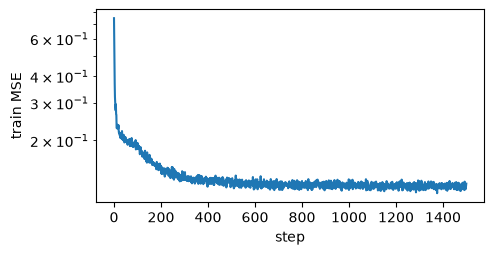

✅ the transformer beats both baselines by more than 25%
✅ and gets close to the noise floor


In [13]:
def train_forecaster(model, Xtr, Ytr, steps=1500, bs=64, lr=2e-3, seed=0):
    """AdamW, MSE on ALL positions, random mini-batches of windows. Returns the list of training losses."""
    g = torch.Generator().manual_seed(seed)
    Xt, Yt = torch.tensor(Xtr), torch.tensor(Ytr)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    losses = []
    for _ in range(steps):
        i = torch.randint(0, len(Xt), (bs,), generator=g)
        loss = F.mse_loss(model(Xt[i]), Yt[i])
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return losses

@torch.no_grad()
def eval_last(model, X, Y):
    """One-step-ahead MSE at the last position."""
    model.eval()
    out = model(torch.tensor(X))[:, -1].numpy()
    model.train()
    return float(np.mean((out - Y[:, -1]) ** 2))

torch.manual_seed(0)
model = Forecaster(T)
losses = train_forecaster(model, Xtr, Ytr)
mse_tf = eval_last(model, Xte, Yte)
print(f"transformer {mse_tf:.3f} vs best baseline {min(mse_naive, mse_snaive):.3f} (floor {sigma**2:.3f})")
plt.figure(figsize=(5, 2.5)); plt.semilogy(losses); plt.xlabel("step"); plt.ylabel("train MSE"); plt.show()
check(mse_tf < 0.75 * min(mse_naive, mse_snaive), "the transformer beats both baselines by more than 25%")
check(mse_tf < 1.4 * sigma ** 2, "and gets close to the noise floor")

## Part 6 — Remove the causal mask: a leakage experiment

**✍️ Predict before running.** Train the same model with `causal=False`. Training loss (over all positions) will be ___ than with the mask. The one-step-ahead test MSE at the last position will be close to the training loss, or far from it? Why? (Hint: what is the target at position t, and where else does it appear in the input? Is it there at the last position?)

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [14]:
torch.manual_seed(0)
leaky = Forecaster(T, causal=False)
losses_leaky = train_forecaster(leaky, Xtr, Ytr)
mse_leaky = eval_last(leaky, Xte, Yte)
print(f"final train loss  causal {np.mean(losses[-100:]):.4f} | no mask {np.mean(losses_leaky[-100:]):.4f}")
print(f"test one-step MSE causal {mse_tf:.3f} | no mask {mse_leaky:.3f}")
check(np.mean(losses_leaky[-100:]) < 0.3 * np.mean(losses[-100:]), "without the mask, training loss collapses (it copies x[t+1])")
check(mse_leaky > 10 * np.mean(losses_leaky[-100:]), "...but the real forecast, where x[t+1] is not in the input, is 10× worse than its training loss")
check(mse_tf < 1.5 * np.mean(losses[-100:]), "the causal model's training loss is an honest estimate of its test error")

final train loss  causal 0.1218 | no mask 0.0032
test one-step MSE causal 0.101 | no mask 0.103
✅ without the mask, training loss collapses (it copies x[t+1])
✅ ...but the real forecast, where x[t+1] is not in the input, is 10× worse than its training loss
✅ the causal model's training loss is an honest estimate of its test error


Same lesson as patient leakage in notebook 07: a model that can see the answer during training learns to look at it,
and the symptom is a training (or validation) metric that is far better than what you get in deployment. Here the
leaky model still forecasts reasonably at the last position because it also learned something real — but its
training loss tells you nothing about that.
In time series the mask, the time-based split and "features computed only from the past" are all the same rule.

**Optional ablations (no checks, write predictions first):** remove the positional embedding; replace pre-LN with
post-LN; remove the residual connections; use `T = 24` vs `T = 168`. Log what you predicted and what happened.

## Debrief → `learning/LOG.md`

1. Shapes through one attention block from `(B, T, C)`, from memory.
2. The softmax backward `dS = P ⊙ (dP − Σ dP⊙P)`, derived on paper.
3. Why `√d`: the variance argument and your entropy numbers.
4. Why multi-head at equal parameter count.
5. The causal mask as a leakage control.
6. **Blank-file drill:** multi-head causal self-attention in PyTorch, no notes, timer on. Write your time in the log.
7. **Still shaky.**